# Buying in London: Housing Affordability and Borough Trends, 2015–2025
## Dataset selection

Source: Office for National Statistics (ONS), House price to
workplace-based earnings ratio, 2025 release.

I chose this dataset to explore how housing affordability differs
between London boroughs and how it has changed over time.

I use sheets 5a, 5b and 5c: median house prices, median annual
workplace-based earnings and house-price-to-earnings ratios.

The analysis covers London's 32 boroughs and the City of London
from 2015 to 2025: 33 local authorities and 363 area-year records.
The ONS bulletin was published on 26 March 2026.

The intended audience is potential London homebuyers, with historical
context for people researching property investment. The analysis
does not forecast investment returns.

[ONS source bulletin and associated datasets](https://www.ons.gov.uk/peoplepopulationandcommunity/housing/bulletins/housingaffordabilityinenglandandwales/2025)

A higher ratio means homes are less affordable relative to earnings.
Workplace-based earnings refer to people working in an area,
who may live elsewhere.

Main question: How did house prices and workplace earnings relate
to changes in London’s housing affordability between 2015 and 2025,
particularly since 2021?

I will analyse affordability ratios alongside median house prices
and median annual workplace-based earnings.

In [1]:
import pandas as pd

file_path = "aff1ratioofhousepricetoworkplacebasedearnings.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="5c",
    header=1
)

df.head()

,Country/Region code,Country/Region name,Local authority code,Local authority name,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,5-Year Average
0,E12000001,North East,E06000001,Hartlepool,2.64,2.74,2.85,3.02,2.75,2.9,3.2,3.19,2.88,4.2,5.02,5.23,4.70,4.73,4.48,4.14,4.26,4.65,4.69,4.6,4.8,4.82,5.00,4.63,4.94,4.65,4.73,4.59,4.8,4.74
1,E12000001,North East,E06000002,Middlesbrough,2.83,2.74,2.89,2.73,2.58,2.47,2.56,3.49,4.17,4.9,5.27,4.69,4.87,5.02,4.67,4.26,4.48,5.01,5.01,5.09,4.88,5.28,5.15,5,5.42,4.95,4.74,4.8,4.51,4.88
2,E12000001,North East,E06000003,Redcar and Cleveland,2.34,2.45,2.12,2.21,2.39,2.69,3.4,3.64,3.99,5.02,5.09,4.74,4.52,4.97,4.41,4.86,4.62,4.65,4.67,5.31,5.11,5.11,5.03,5.15,5.84,5.67,5.2,5.38,4.68,5.35
3,E12000001,North East,E06000004,Stockton-on-Tees,2.97,2.93,3.05,3.06,3.07,3.53,4.29,4.84,5.38,5.72,5.84,5.79,5.19,5.53,5.25,5.34,5.28,5.3,5.33,5.02,5.64,5.5,5.06,5.01,5.56,5.22,5.73,5.58,4.78,5.37
4,E12000001,North East,E06000005,Darlington,3.04,3.46,3.14,3.24,3.19,3.18,3.94,5.2,6.01,5.72,5.35,5.45,5.30,5.62,5.14,5.05,5.64,4.9,4.93,4.92,5.37,5.34,5.04,5.35,5.53,5.27,5.45,4.8,5.26,5.26


## Initial Data Exploration

Before cleaning, I will inspect the dataset's size, column names,
data types and final rows to understand its structure.

In [2]:
# Number of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
print(df.columns.tolist())

Rows: 318
Columns: 34
['Country/Region code', 'Country/Region name', 'Local authority code', 'Local authority name', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '5-Year Average']


In [3]:
# Data types and non-missing counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318 entries, 0 to 317
Data columns (total 34 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country/Region code   318 non-null    object 
 1   Country/Region name   318 non-null    object 
 2   Local authority code  318 non-null    object 
 3   Local authority name  318 non-null    object 
 4   1997                  318 non-null    object 
 5   1998                  318 non-null    object 
 6   1999                  318 non-null    object 
 7   2000                  318 non-null    object 
 8   2001                  318 non-null    object 
 9   2002                  318 non-null    object 
 10  2003                  318 non-null    object 
 11  2004                  318 non-null    object 
 12  2005                  318 non-null    object 
 13  2006                  318 non-null    object 
 14  2007                  318 non-null    object 
 15  2008                  3

In [4]:
# Check the final rows for notes or other non-data content
df.tail()

,Country/Region code,Country/Region name,Local authority code,Local authority name,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,5-Year Average
313,W92000004,Wales,W06000020,Torfaen,2.46,2.63,2.69,2.85,2.72,3.05,3.65,4.51,4.69,5.02,5.83,5.72,5.12,5.16,5.48,5.39,4.94,5.1,4.97,4.84,4.85,5.31,5.41,5.49,5.82,5.59,5.42,5.02,5.55,5.48
314,W92000004,Wales,W06000021,Monmouthshire,4.15,4.72,4.64,5.31,5.97,6.97,6.75,7.98,8.44,8.83,9.68,8.63,7.84,8.1,8.09,8.5,7.88,8.17,8.93,8.51,8.42,8.66,8.69,8.59,10.25,9.96,9.41,8.57,7.98,9.23
315,W92000004,Wales,W06000022,Newport,2.87,2.67,2.9,3.15,3.25,3.77,4.44,5.38,5.78,5.81,5.91,5.66,5.34,5.24,5.07,5.19,5.23,5.48,5.96,6.11,5.99,6.08,6.18,6.31,7.35,6.9,7.46,6.88,6.28,6.97
316,W92000004,Wales,W06000023,Powys,3.68,3.71,3.91,4.38,4.03,4.66,5.24,7.5,7.96,7.93,8.66,8.59,7.39,8.28,8.08,7.97,7.76,8.2,7.2,7.19,7.46,7.51,6.90,6.31,8.02,8.21,7.91,7.34,7.86,7.87
317,W92000004,Wales,W06000024,Merthyr Tydfil,1.92,2.09,2.27,2.36,2.17,2.28,2.27,3.02,3.85,4.48,5.02,4.72,4.34,4.4,4.03,4.08,3.92,4.37,4.25,3.83,4.14,3.74,4.09,4.61,4.94,4.87,4.84,4.9,4.57,4.82


## Data Quality Checks

I will check for duplicate rows and unavailable values before cleaning.
The ONS metadata defines [x] as no data available.

The analysis focuses on London during 2015–2025. I check and clean
the wider England and Wales dataset before selecting London.

The 10 unavailable ratios occur outside London, in the Isles of Scilly.
The selected London data contains no missing ratios.

In [5]:
years = [str(year) for year in range(2015, 2026)]

print("Duplicate rows:", df.duplicated().sum())

print("\nUnavailable values by year:")
print(df[years].eq("[x]").sum())

print("\nTotal unavailable values:")
print(df[years].eq("[x]").sum().sum())

Duplicate rows: 0

Unavailable values by year:
2015    1
2016    1
2017    1
2018    1
2019    0
2020    1
2021    1
2022    1
2023    1
2024    1
2025    1
dtype: int64

Total unavailable values:
10


In [6]:
# Show areas with unavailable values during 2015–2025
missing_rows = df[years].eq("[x]").any(axis=1)

df.loc[
    missing_rows,
    ["Country/Region name", "Local authority name"] + years
]

,Country/Region name,Local authority name,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
277,South West,Isles of Scilly,[x],[x],[x],[x],16.96,[x],[x],[x],[x],[x],[x]


## Data Cleaning

No duplicate rows were found, so none were removed.

There are 10 unavailable values, marked [x], all belonging to
the Isles of Scilly. Its 2019 ratio is available.

I will convert [x] to missing values and annual ratios to numeric
types. I will not fill missing ratios because there is insufficient
evidence to estimate them reliably.

I will retain area identifiers and years 2015–2025, excluding
earlier years and the five-year average to match the analysis scope.
The original DataFrame will remain unchanged.

In [7]:
# Keep area details and the selected years
area_columns = [
    "Country/Region code",
    "Country/Region name",
    "Local authority code",
    "Local authority name"
]

clean_df = df[area_columns + years].copy()

# Recognise unavailable values, then convert ratios to numbers
clean_df[years] = clean_df[years].mask(clean_df[years].eq("[x]"))
clean_df[years] = clean_df[years].apply(pd.to_numeric, errors="raise")

# Check the result
print("Shape:", clean_df.shape)
print("Missing values:", clean_df[years].isna().sum().sum())

clean_df[years].dtypes

Shape: (318, 15)
Missing values: 10


2015    float64
2016    float64
2017    float64
2018    float64
2019    float64
2020    float64
2021    float64
2022    float64
2023    float64
2024    float64
2025    float64
dtype: object

### Reshaping the data

I will convert the separate year columns into a single year column
and a single affordability_ratio column.

This makes it easier to group, compare and plot values over time.
Missing values will remain missing.

In [8]:
long_df = clean_df.melt(
    id_vars=area_columns,
    value_vars=years,
    var_name="year",
    value_name="affordability_ratio"
)

long_df["year"] = long_df["year"].astype(int)

# Create the London subset
london_df = long_df[
    long_df["Country/Region name"] == "London"
].copy()

print("Full dataset:", long_df.shape)
print("London dataset:", london_df.shape)
print(
    "London missing ratios:",
    london_df["affordability_ratio"].isna().sum()
)

london_df.head()

Full dataset: (3498, 6)
London dataset: (363, 6)
London missing ratios: 0


,Country/Region code,Country/Region name,Local authority code,Local authority name,year,affordability_ratio
172,E12000007,London,E09000001,City of London,2015,15.25
173,E12000007,London,E09000002,Barking and Dagenham,2015,7.12
174,E12000007,London,E09000003,Barnet,2015,14.24
175,E12000007,London,E09000004,Bexley,2015,9.14
176,E12000007,London,E09000005,Brent,2015,13.34


## Exploring House Prices and Earnings

To understand changes in affordability, I will also examine
sheet 5a (median house prices) and sheet 5b (median annual
workplace-based earnings) from the same ONS workbook.

I will inspect these sheets before cleaning and combining them
with the affordability ratios.

In [9]:
# Load the additional sheets without changing existing data
prices_df = pd.read_excel(file_path, sheet_name="5a", header=1)
earnings_df = pd.read_excel(file_path, sheet_name="5b", header=1)

print("House prices:", prices_df.shape)
print("Earnings:", earnings_df.shape)

print("\nHouse-price columns:")
print(prices_df.columns.tolist())

print("\nEarnings columns:")
print(earnings_df.columns.tolist())

House prices: (318, 33)
Earnings: (318, 33)

House-price columns:
['Country/Region code', 'Country/Region name', 'Local authority code', 'Local authority name', 'Year ending Sep 1997', 'Year ending Sep 1998', 'Year ending Sep 1999', 'Year ending Sep 2000', 'Year ending Sep 2001', 'Year ending Sep 2002', 'Year ending Sep 2003', 'Year ending Sep 2004', 'Year ending Sep 2005', 'Year ending Sep 2006', 'Year ending Sep 2007', 'Year ending Sep 2008', 'Year ending Sep 2009', 'Year ending Sep 2010', 'Year ending Sep 2011', 'Year ending Sep 2012', 'Year ending Sep 2013', 'Year ending Sep 2014', 'Year ending Sep 2015', 'Year ending Sep 2016', 'Year ending Sep 2017', 'Year ending Sep 2018', 'Year ending Sep 2019', 'Year ending Sep 2020', 'Year ending Sep 2021', 'Year ending Sep 2022', 'Year ending Sep 2023', 'Year ending Sep 2024', 'Year ending Sep 2025']

Earnings columns:
['Country/Region code', 'Country/Region name', 'Local authority code', 'Local authority name', '1997', '1998', '1999', '2000

In [10]:
# Work on copies so the original imports stay unchanged
prices_clean = prices_df.copy()
earnings_clean = earnings_df.copy()

# Standardise column headings
prices_clean.columns = (
    prices_clean.columns.astype(str)
    .str.replace("Year ending Sep ", "", regex=False)
    .str.strip()
)

earnings_clean.columns = (
    earnings_clean.columns.astype(str).str.strip()
)

# Keep area identifiers and 2015–2025
prices_clean = prices_clean[area_columns + years].copy()
earnings_clean = earnings_clean[area_columns + years].copy()

# Check data quality before converting values
for name, data in [
    ("House prices", prices_clean),
    ("Earnings", earnings_clean)
]:
    print(f"\n{name}")
    print("Duplicate rows:", data.duplicated().sum())
    print("Blank annual values:", data[years].isna().sum().sum())
    print("[x] markers:", data[years].eq("[x]").sum().sum())


House prices
Duplicate rows: 0
Blank annual values: 0
[x] markers: 0

Earnings
Duplicate rows: 0
Blank annual values: 0
[x] markers: 10


### Cleaning and combining prices and earnings

No duplicate rows were found in either selected table.
House prices contain no missing values, while earnings contain
10 unavailable values marked [x].

I will convert these markers to missing values without estimating
replacements, and convert prices and earnings to numeric types.

I will reshape both tables and join them to the ratios using
local authority code and year. Each join must be one-to-one
to prevent accidental duplication.

In [11]:
# Convert unavailable markers and numeric values
for data in [prices_clean, earnings_clean]:
    data[years] = data[years].mask(data[years].eq("[x]"))
    data[years] = data[years].apply(pd.to_numeric, errors="raise")

# Reshape house prices
prices_long = prices_clean.melt(
    id_vars=area_columns,
    value_vars=years,
    var_name="year",
    value_name="median_house_price"
)

# Reshape earnings
earnings_long = earnings_clean.melt(
    id_vars=area_columns,
    value_vars=years,
    var_name="year",
    value_name="median_annual_earnings"
)

prices_long["year"] = prices_long["year"].astype(int)
earnings_long["year"] = earnings_long["year"].astype(int)

# Combine using area code and year
join_keys = ["Local authority code", "year"]

analysis_df = long_df.merge(
    prices_long[join_keys + ["median_house_price"]],
    on=join_keys,
    how="left",
    validate="one_to_one"
).merge(
    earnings_long[join_keys + ["median_annual_earnings"]],
    on=join_keys,
    how="left",
    validate="one_to_one"
)

# Keep the London subset in a new variable
london_analysis = analysis_df[
    analysis_df["Country/Region name"] == "London"
].copy()

print("Combined dataset:", analysis_df.shape)
print("London dataset:", london_analysis.shape)

print("\nMissing values:")
print(analysis_df[
    ["affordability_ratio", "median_house_price", "median_annual_earnings"]
].isna().sum())

london_analysis.head()

Combined dataset: (3498, 8)
London dataset: (363, 8)

Missing values:
affordability_ratio       10
median_house_price         0
median_annual_earnings    10
dtype: int64


,Country/Region code,Country/Region name,Local authority code,Local authority name,year,affordability_ratio,median_house_price,median_annual_earnings
172,E12000007,London,E09000001,City of London,2015,15.25,823750,54034.0
173,E12000007,London,E09000002,Barking and Dagenham,2015,7.12,235000,33018.0
174,E12000007,London,E09000003,Barnet,2015,14.24,440000,30900.0
175,E12000007,London,E09000004,Bexley,2015,9.14,271000,29664.0
176,E12000007,London,E09000005,Brent,2015,13.34,400000,29987.0


In [12]:
calculated_ratio = (
    analysis_df["median_house_price"]
    / analysis_df["median_annual_earnings"]
)

difference = (
    calculated_ratio - analysis_df["affordability_ratio"]
).abs()

print("Largest ratio difference:", difference.max())
print(
    "Duplicate area-year records:",
    analysis_df.duplicated(["Local authority code", "year"]).sum()
)

Largest ratio difference: 0.005000000000000782
Duplicate area-year records: 0


## Analytical Questions

1. Which London areas became more affordable between 2021 and
   2025 despite rising median house prices?

2. How did changes in house prices and earnings contribute to
   affordability improvements over that period?

3. In 2025, did areas with higher workplace earnings necessarily
   have more affordable housing?

4. Were improvements since 2021 widespread across London or
   concentrated in a few areas?

5. Which areas remained less affordable in 2025 than in 2015,
   despite improving since 2021?

These questions investigate changes in prices and earnings.
They do not establish causes such as office growth or regeneration.

## Analysis: Changes Between 2021 and 2025

I will calculate percentage changes in median house prices,
median annual workplace earnings and affordability ratios
for each London local authority.

2021 is a reference year, not necessarily each area's peak.
A negative change in the affordability ratio indicates improvement.

These comparisons describe changes in the published estimates.
They do not establish causes such as regeneration or office growth.

In [13]:
# Arrange the three measures by area and year
comparison = london_analysis.pivot(
    index=["Local authority code", "Local authority name"],
    columns="year",
    values=[
        "median_house_price",
        "median_annual_earnings",
        "affordability_ratio"
    ]
)

# Create one summary row per London local authority
changes = pd.DataFrame(index=comparison.index)

for measure, label in [
    ("median_house_price", "price"),
    ("median_annual_earnings", "earnings"),
    ("affordability_ratio", "ratio")
]:
    changes[f"{label}_2021"] = comparison[(measure, 2021)]
    changes[f"{label}_2025"] = comparison[(measure, 2025)]

    changes[f"{label}_change_pct"] = (
        changes[f"{label}_2025"]
        / changes[f"{label}_2021"] - 1
    ) * 100

changes = changes.reset_index()

# Question 1: improvement despite rising house prices
improved_with_rising_prices = changes[
    (changes["price_change_pct"] > 0)
    & (changes["ratio_change_pct"] < 0)
].sort_values("ratio_change_pct")

print("London areas analysed:", len(changes))
print(
    "Areas improving despite rising prices:",
    len(improved_with_rising_prices)
)

improved_with_rising_prices[
    [
        "Local authority name",
        "price_change_pct",
        "earnings_change_pct",
        "ratio_change_pct"
    ]
].round(2)

London areas analysed: 33
Areas improving despite rising prices: 19


,Local authority name,price_change_pct,earnings_change_pct,ratio_change_pct
9,Enfield,3.48,29.95,-20.36
22,Lewisham,2.58,28.41,-20.14
13,Haringey,6.06,31.17,-19.13
28,Sutton,7.06,29.62,-17.44
5,Bromley,6.06,26.26,-15.99
24,Newham,3.18,20.94,-14.63
8,Ealing,5.42,22.57,-13.96
20,Kingston upon Thames,2.57,18.57,-13.47
15,Havering,12.50,28.35,-12.39
7,Croydon,3.16,14.67,-10.00


### Comparing groups of areas

I group local authorities by whether median house prices rose, fell
or stayed unchanged between 2021 and 2025. Within each group, I
summarise the median percentage changes in earnings and affordability.
These are summaries of local-authority changes, not London-wide ratios.

In [14]:
# Compare groups defined by the direction of house-price change
grouped_changes = changes.copy()
grouped_changes["price_direction"] = "Unchanged"
grouped_changes.loc[grouped_changes["price_change_pct"] > 0, "price_direction"] = "Rose"
grouped_changes.loc[grouped_changes["price_change_pct"] < 0, "price_direction"] = "Fell"

price_group_summary = (
    grouped_changes.groupby("price_direction")
    .agg(
        number_of_areas=("Local authority code", "count"),
        median_earnings_change_pct=("earnings_change_pct", "median"),
        median_ratio_change_pct=("ratio_change_pct", "median")
    )
    .reindex(["Rose", "Fell", "Unchanged"])
)
display(price_group_summary.round(2))

,number_of_areas,median_earnings_change_pct,median_ratio_change_pct
price_direction,,,
Rose,19,20.53,-10.00
Fell,13,26.79,-23.00
Unchanged,1,12.46,-11.05


Prices rose in 19 areas, fell in 13 and remained unchanged in one.
This separates improvements accompanied by falling prices from those
achieved despite rising prices.

### Finding 1: Improving affordability does not always mean falling prices

Between 2021 and 2025, 19 of London's 33 local authorities
(approximately 58%) recorded rising median house prices alongside
falling affordability ratios.

In these areas, earnings grew faster than house prices.
However, an improving ratio does not necessarily mean homes
are affordable or mortgage payments have fallen.

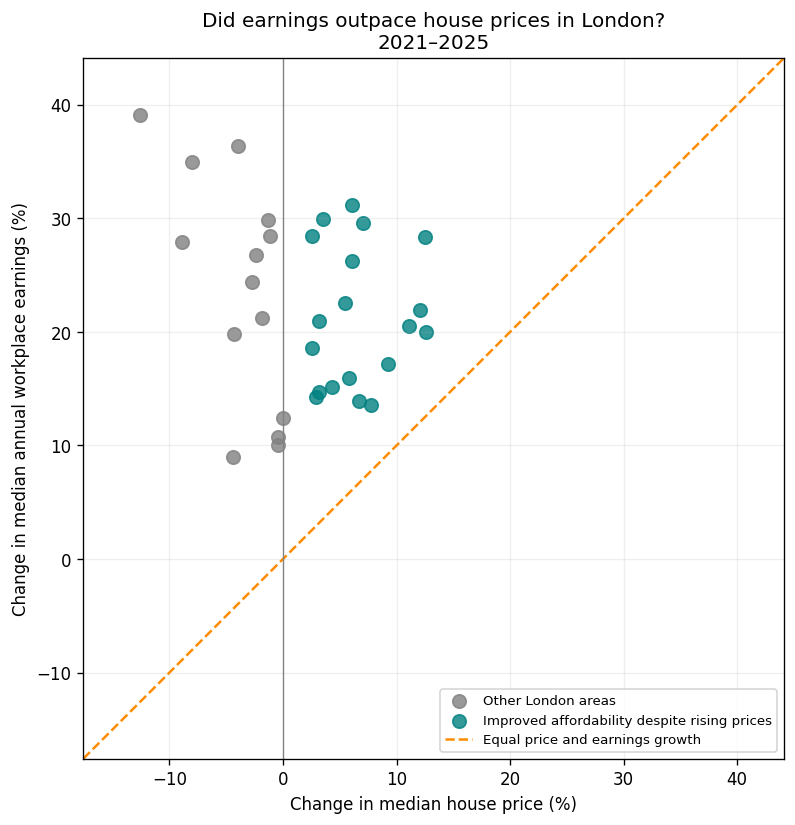

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 7))

# Identify areas where prices rose but affordability improved
highlight = (
    (changes["price_change_pct"] > 0)
    & (changes["ratio_change_pct"] < 0)
)

# Plot the remaining London areas
ax.scatter(
    changes.loc[~highlight, "price_change_pct"],
    changes.loc[~highlight, "earnings_change_pct"],
    color="grey",
    s=65,
    alpha=0.8,
    label="Other London areas"
)

# Highlight improving areas with rising house prices
ax.scatter(
    changes.loc[highlight, "price_change_pct"],
    changes.loc[highlight, "earnings_change_pct"],
    color="teal",
    s=65,
    alpha=0.8,
    label="Improved affordability despite rising prices"
)

# Use matching axis scales
low = min(
    changes["price_change_pct"].min(),
    changes["earnings_change_pct"].min(),
    0
) - 5

high = max(
    changes["price_change_pct"].max(),
    changes["earnings_change_pct"].max()
) + 5

# Equal growth leaves the price-to-earnings ratio unchanged
ax.plot(
    [low, high],
    [low, high],
    linestyle="--",
    color="darkorange",
    linewidth=1.5,
    label="Equal price and earnings growth"
)

# Mark where house prices did not change
ax.axvline(0, color="grey", linewidth=0.8)

ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_aspect("equal", adjustable="box")

ax.set_title(
    "Did earnings outpace house prices in London?\n2021–2025"
)
ax.set_xlabel("Change in median house price (%)")
ax.set_ylabel("Change in median annual workplace earnings (%)")

ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.show()

In [16]:
print(
    "Areas where earnings grew faster than prices:",
    (changes["earnings_change_pct"]
     > changes["price_change_pct"]).sum()
)

print(
    "Areas where affordability ratios fell:",
    (changes["ratio_change_pct"] < 0).sum()
)

print(
    "Areas where house prices fell:",
    (changes["price_change_pct"] < 0).sum()
)

print(
    "Areas where house prices stayed unchanged:",
    (changes["price_change_pct"] == 0).sum()
)

Areas where earnings grew faster than prices: 33
Areas where affordability ratios fell: 33
Areas where house prices fell: 13
Areas where house prices stayed unchanged: 1


### Were improvements widespread?

All 33 London local authorities recorded lower affordability
ratios in 2025 than in 2021. The improvement was therefore
widespread rather than limited to a few expensive areas.

House prices rose in 19 areas, fell in 13 and stayed unchanged
in one. Earnings grew faster than prices in every area.

These are improvements in the published price-to-earnings measure,
not evidence that every household could afford a home or faced
lower mortgage payments.

In [17]:
changes[
    [
        "Local authority name",
        "price_change_pct",
        "earnings_change_pct",
        "ratio_change_pct"
    ]
].sort_values("ratio_change_pct").round(2)

,Local authority name,price_change_pct,earnings_change_pct,ratio_change_pct
29,Tower Hamlets,-12.59,39.09,-37.13
19,Kensington and Chelsea,-8.00,35.00,-31.86
21,Lambeth,-3.94,36.39,-29.57
12,Hammersmith and Fulham,-8.93,27.95,-28.82
6,Camden,-1.28,29.85,-23.97
31,Wandsworth,-1.17,28.47,-23.08
18,Islington,-2.34,26.79,-23.00
11,Hackney,-2.74,24.36,-21.81
9,Enfield,3.48,29.95,-20.36
32,Westminster,-4.31,19.83,-20.16


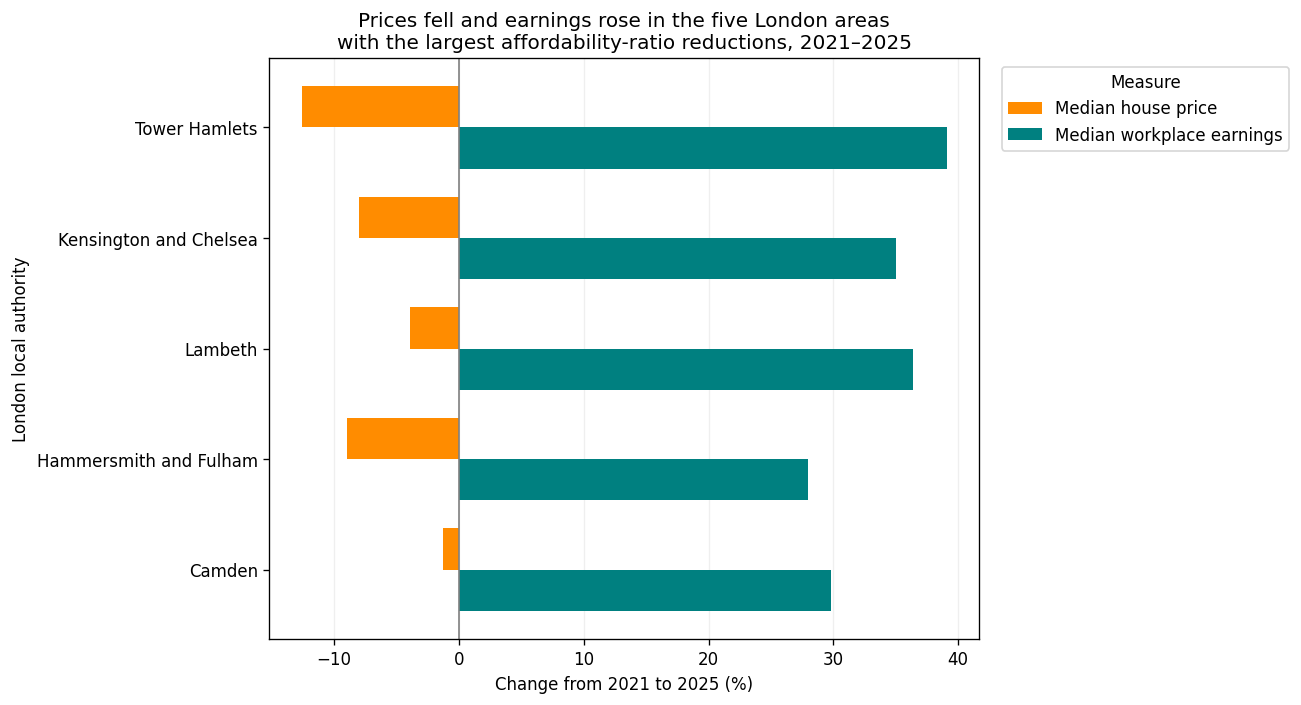

In [18]:
# Select the five largest affordability-ratio reductions
top_five = changes.nsmallest(5, "ratio_change_pct")

plot_data = top_five.set_index("Local authority name")[
    ["price_change_pct", "earnings_change_pct"]
].rename(columns={
    "price_change_pct": "Median house price",
    "earnings_change_pct": "Median workplace earnings"
})

ax = plot_data.plot.barh(
    figsize=(11, 6),
    color=["darkorange", "teal"],
    width=0.75
)

ax.invert_yaxis()
ax.axvline(0, color="grey", linewidth=1)

ax.set_title(
    "Prices fell and earnings rose in the five London areas\n"
    "with the largest affordability-ratio reductions, 2021–2025"
)
ax.set_xlabel("Change from 2021 to 2025 (%)")
ax.set_ylabel("London local authority")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(
    title="Measure",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

### Finding 2: Two changes supported the largest improvements

The five London areas with the largest affordability-ratio reductions
between 2021 and 2025 all recorded falling median house prices
alongside rising median workplace earnings.

Tower Hamlets recorded a 12.59% fall in median house prices and
39.09% earnings growth, alongside a 37.13% reduction in its ratio.

These are changes in area-level estimates, not pay rises for the
same individual workers. Changes in the mix of properties sold
can also affect median house prices.

## Question 3: Do Higher Workplace Earnings Mean More Affordable Housing?

I will compare median workplace earnings, median house prices
and affordability ratios across London's local authorities in 2025.

Earnings are already part of the ratio calculation, so any
relationship must be interpreted carefully. Workplace earnings
also describe people working in an area, not necessarily its residents.

In [19]:
# Select London's 2025 data
london_2025 = london_analysis[
    london_analysis["year"] == 2025
].copy()

# Inspect the 10 areas with the highest workplace earnings
london_2025[
    [
        "Local authority name",
        "median_annual_earnings",
        "median_house_price",
        "affordability_ratio"
    ]
].sort_values(
    "median_annual_earnings",
    ascending=False
).head(10).round(2)

,Local authority name,median_annual_earnings,median_house_price,affordability_ratio
3352,City of London,68663.0,762500,11.10
3381,Tower Hamlets,66686.0,500000,7.50
3384,Westminster,53923.0,865000,16.04
3358,Camden,53577.0,770000,14.37
3370,Islington,53185.0,625000,11.75
3364,Hammersmith and Fulham,50435.0,700000,13.88
3379,Southwark,50000.0,540000,10.80
3363,Hackney,48724.0,580000,11.90
3373,Lambeth,48690.0,538000,11.05
3371,Kensington and Chelsea,45600.0,1150000,25.22


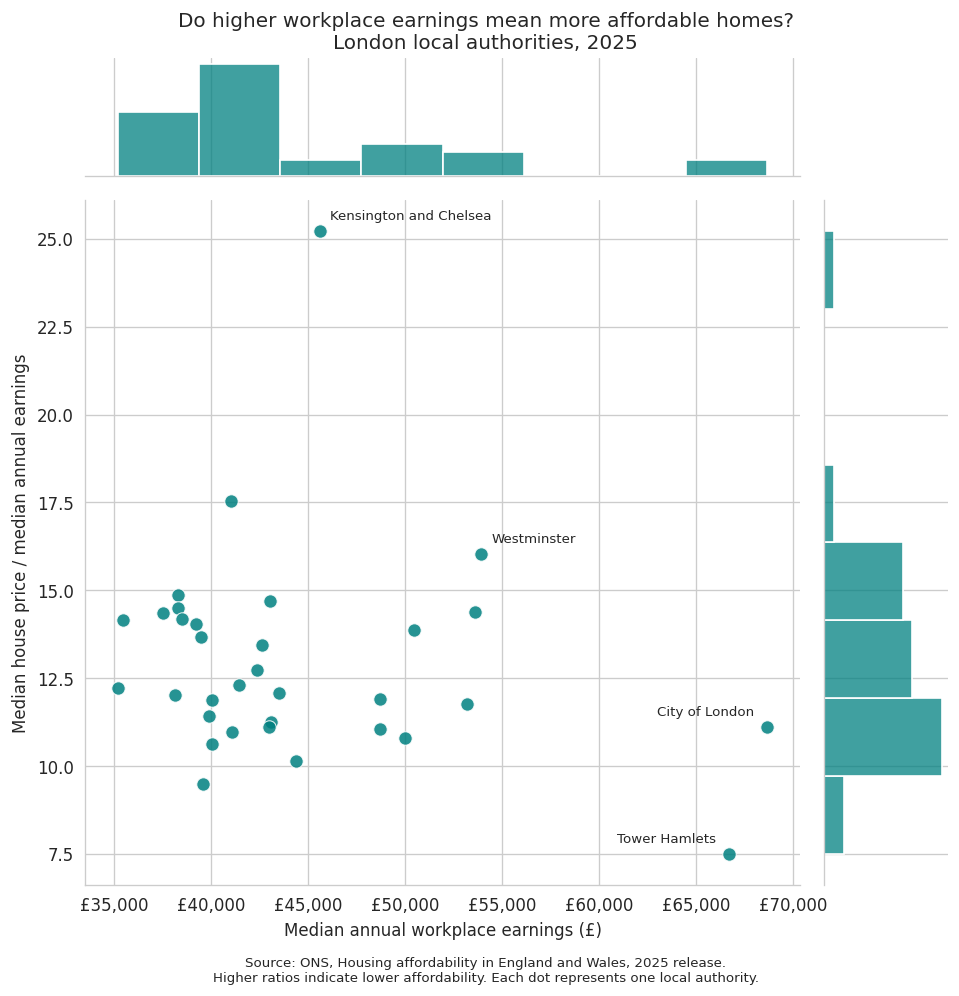

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Select London's 2025 data
london_2025 = london_analysis[
    london_analysis["year"] == 2025
].copy()

with sns.axes_style("whitegrid"):

    # Scatter plot with distributions along the edges
    g = sns.jointplot(
        data=london_2025,
        x="median_annual_earnings",
        y="affordability_ratio",
        kind="scatter",
        color="teal",
        height=8,
        ratio=5,
        marginal_kws={"bins": 8},
        joint_kws={"s": 65, "alpha": 0.85}
    )

    # Label contrasting examples
    selected = [
        "Tower Hamlets",
        "Westminster",
        "Kensington and Chelsea",
        "City of London"
    ]

    for _, row in london_2025[
        london_2025["Local authority name"].isin(selected)
    ].iterrows():

        # Put labels for high-earning areas to the left
        place_left = row["median_annual_earnings"] > 60000

        g.ax_joint.annotate(
            row["Local authority name"],
            (
                row["median_annual_earnings"],
                row["affordability_ratio"]
            ),
            xytext=(-8 if place_left else 6, 7),
            textcoords="offset points",
            ha="right" if place_left else "left",
            fontsize=8
        )

    # Labels and currency formatting
    g.set_axis_labels(
        "Median annual workplace earnings (£)",
        "Median house price / median annual earnings"
    )

    g.ax_joint.xaxis.set_major_formatter(
        StrMethodFormatter("£{x:,.0f}")
    )

    # Title
    g.fig.suptitle(
        "Do higher workplace earnings mean more affordable homes?\n"
        "London local authorities, 2025",
        y=1.03
    )

    # Source caption
    g.fig.subplots_adjust(bottom=0.12)

    g.fig.text(
        0.5,
        0.02,
        "Source: ONS, Housing affordability in England and Wales, "
        "2025 release.\n"
        "Higher ratios indicate lower affordability. Each dot "
        "represents one local authority.",
        ha="center",
        fontsize=8
    )

    plt.show()

### Finding 3: Higher workplace earnings do not guarantee affordability

Tower Hamlets has median workplace earnings of £66,686 and an
affordability ratio of 7.50. Westminster also has relatively high
earnings (£53,923), but its ratio is much higher at 16.04.

Kensington and Chelsea stands out with a ratio of 25.22:
its median house price is £1.15 million compared with median
workplace earnings of £45,600.

Affordability therefore depends on house prices relative to earnings,
not earnings alone. These figures describe local workers, not
necessarily residents. Earnings are also part of the ratio itself,
so this chart does not establish an independent causal relationship.

## Question 4: Were Improvements Widespread Across London?

I will compare each area's affordability ratio with its own
2021 value, indexed to 100.

Values below 100 indicate improved affordability relative to 2021.
Values above 100 indicate worse affordability.

This compares changes, not absolute affordability levels.
2021 is a reference year, not necessarily each area's peak.

In [21]:
# Put years into columns and London areas into rows
ratio_by_year = london_analysis.pivot(
    index="Local authority name",
    columns="year",
    values="affordability_ratio"
)

# Set each area's 2021 ratio to 100
ratio_index = ratio_by_year.div(
    ratio_by_year[2021],
    axis=0
) * 100

# Sort by the 2025 index
ratio_index = ratio_index.sort_values(2025)

print(
    "Areas below their 2021 ratio in 2025:",
    (ratio_index[2025] < 100).sum()
)

ratio_index[[2015, 2021, 2025]].round(1)

Areas below their 2021 ratio in 2025: 33


year,2015,2021,2025
Local authority name,,,
Tower Hamlets,73.5,100.0,62.9
Kensington and Chelsea,102.4,100.0,68.1
Lambeth,82.3,100.0,70.4
Hammersmith and Fulham,108.1,100.0,71.2
Camden,97.9,100.0,76.0
Wandsworth,89.4,100.0,76.9
Islington,103.2,100.0,77.0
Hackney,96.2,100.0,78.2
Enfield,81.7,100.0,79.6


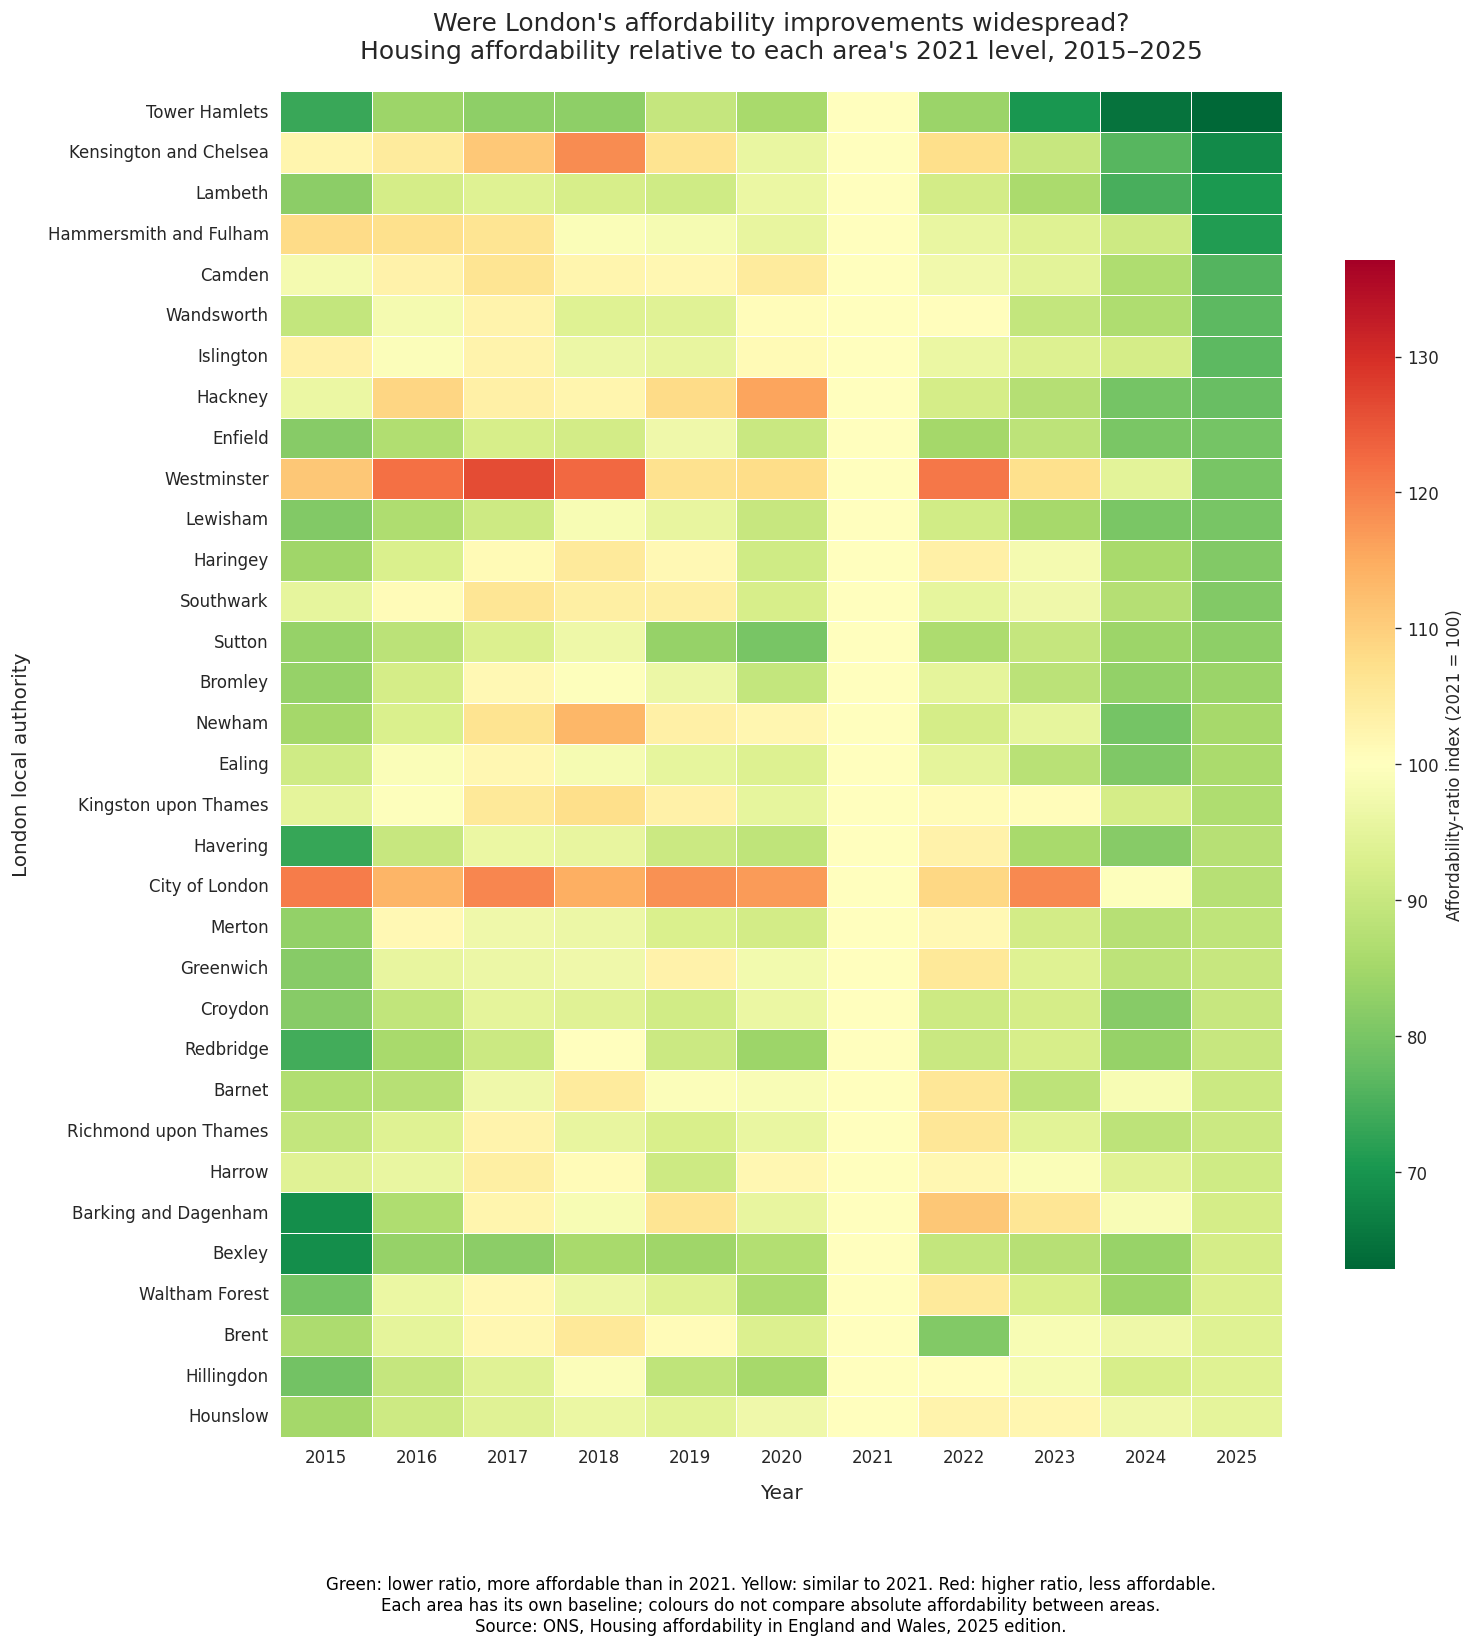

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Reshape the data: one row per area and one column per year
ratio_by_year = london_analysis.pivot(
    index="Local authority name",
    columns="year",
    values="affordability_ratio"
).sort_index(axis=1)

# Compare each area's ratios with its own 2021 value
# 100 = the same as 2021
ratio_index = ratio_by_year.div(ratio_by_year[2021], axis=0) * 100

# Put areas with the largest improvement by 2025 at the top
ratio_index = ratio_index.sort_values(by=2025)

# Keep the colour scale balanced around 100
distance = abs(ratio_index - 100).max().max()

colour_scale = TwoSlopeNorm(
    vmin=100 - distance,
    vcenter=100,
    vmax=100 + distance
)

with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(13, 14), facecolor="white")

    sns.heatmap(
        ratio_index,
        ax=ax,
        cmap="RdYlGn_r",
        norm=colour_scale,
        linewidths=0.4,
        linecolor="white",
        annot=False,
        yticklabels=True,
        xticklabels=True,
        cbar_kws={
            "label": "Affordability-ratio index (2021 = 100)",
            "shrink": 0.75
        }
    )

    ax.set_title(
        "Were London's affordability improvements widespread?\n"
        "Housing affordability relative to each area's 2021 level, 2015–2025",
        fontsize=15,
        pad=20
    )

    ax.set_xlabel("Year", fontsize=12, labelpad=10)
    ax.set_ylabel("London local authority", fontsize=12, labelpad=10)

    ax.tick_params(axis="x", labelrotation=0, labelsize=10)
    ax.tick_params(axis="y", labelrotation=0, labelsize=10)

    fig.text(
        0.5,
        0.025,
        "Green: lower ratio, more affordable than in 2021. "
        "Yellow: similar to 2021. Red: higher ratio, less affordable.\n"
        "Each area has its own baseline; colours do not compare absolute affordability between areas.\n"
        "Source: ONS, Housing affordability in England and Wales, 2025 edition.",
        ha="center",
        fontsize=10,
        color="black"
    )

    plt.tight_layout(rect=[0, 0.09, 1, 1])
    plt.show()

### Finding 4: Improvements were widespread, but varied in size

All 33 London local authorities had lower house-price-to-earnings
ratios in 2025 than in 2021. The reductions ranged from approximately
5% to 37%, showing that improvements were widespread but uneven.

The heatmap compares each area's ratio with its own 2021 level.
A green cell therefore indicates improved affordability relative to
2021, rather than that the area is affordable in absolute terms.

For public-sector monitoring, recent improvements should be considered
alongside current affordability ratios to identify areas where housing
remains particularly expensive relative to workplace earnings.

## Question 5: Has affordability improved recently but remained worse than in 2015?

Compare changes over 2015–2025 with changes over 2021–2025.
This shows whether recent improvements have fully reversed
the longer-term deterioration in affordability.

In [23]:
# Use the original ratios, rather than the indexed values
long_term_changes = ratio_by_year[[2015, 2021, 2025]].copy()

long_term_changes["change_2015_2025_pct"] = (
    (long_term_changes[2025] / long_term_changes[2015]) - 1
) * 100

long_term_changes["change_2021_2025_pct"] = (
    (long_term_changes[2025] / long_term_changes[2021]) - 1
) * 100

# Identify areas that improved recently but remain worse than in 2015
long_term_changes["recent_improvement_but_worse_than_2015"] = (
    (long_term_changes["change_2021_2025_pct"] < 0)
    & (long_term_changes["change_2015_2025_pct"] > 0)
)

number_of_areas = long_term_changes[
    "recent_improvement_but_worse_than_2015"
].sum()

print(
    f"{number_of_areas} of {len(long_term_changes)} London areas "
    "improved since 2021 but remained less affordable than in 2015."
)

display(
    long_term_changes[
        [
            "change_2015_2025_pct",
            "change_2021_2025_pct",
            "recent_improvement_but_worse_than_2015"
        ]
    ]
    .sort_values("change_2015_2025_pct", ascending=False)
    .round(2)
)

15 of 33 London areas improved since 2021 but remained less affordable than in 2015.


year,change_2015_2025_pct,change_2021_2025_pct,recent_improvement_but_worse_than_2015
Local authority name,,,
Bexley,33.70,-7.84,True
Barking and Dagenham,33.43,-8.03,True
Redbridge,21.23,-9.92,True
Havering,19.78,-12.39,True
Hillingdon,18.59,-6.17,True
Waltham Forest,17.05,-6.76,True
Hounslow,11.71,-5.06,True
Greenwich,10.28,-10.10,True
Croydon,10.28,-10.00,True


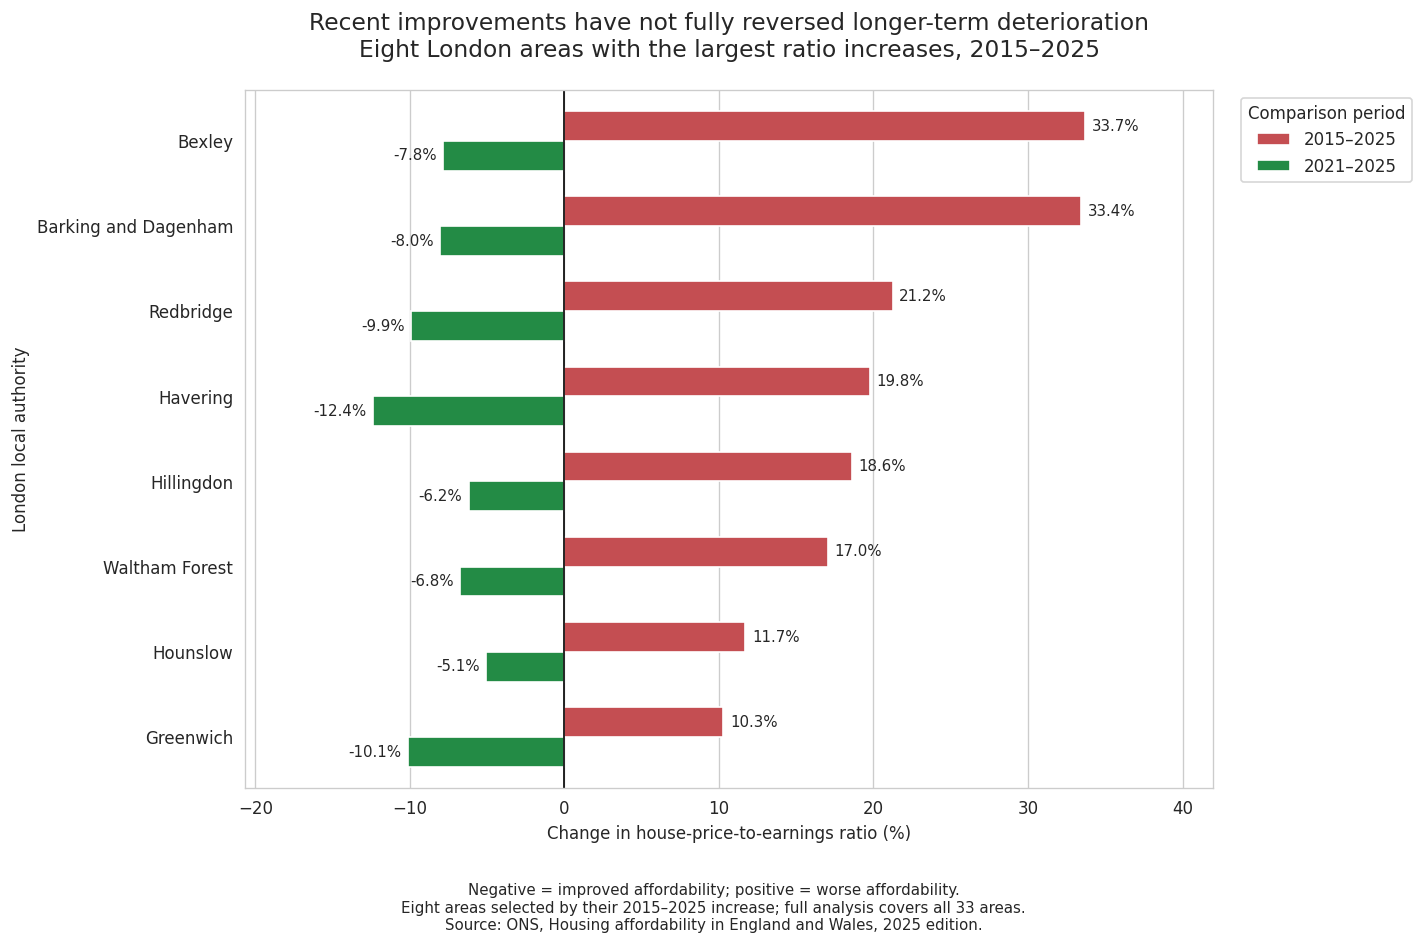

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose the eight areas with the largest deterioration since 2015
chart_data = (
    long_term_changes
    .sort_values("change_2015_2025_pct", ascending=False)
    .head(8)
    [["change_2015_2025_pct", "change_2021_2025_pct"]]
    .rename(columns={
        "change_2015_2025_pct": "2015–2025",
        "change_2021_2025_pct": "2021–2025"
    })
)

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(12, 8), facecolor="white")

    chart_data.plot.barh(
        ax=ax,
        color=["#c44e52", "#238b45"],
        width=0.7
    )

    ax.invert_yaxis()
    ax.axvline(0, color="black", linewidth=1)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=4, fontsize=9)

    ax.set_title(
        "Recent improvements have not fully reversed longer-term deterioration\n"
        "Eight London areas with the largest ratio increases, 2015–2025",
        fontsize=14,
        pad=20
    )

    ax.set_xlabel("Change in house-price-to-earnings ratio (%)")
    ax.set_ylabel("London local authority")

    ax.legend(
        title="Comparison period",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.margins(x=0.18)

    fig.text(
        0.5, 0.025,
        "Negative = improved affordability; positive = worse affordability.\n"
        "Eight areas selected by their 2015–2025 increase; full analysis covers all 33 areas.\n"
        "Source: ONS, Housing affordability in England and Wales, 2025 edition.",
        ha="center",
        fontsize=9
    )

    plt.tight_layout(rect=[0, 0.10, 1, 1])
    plt.show()

### Finding 5: Recent improvement has not meant full recovery everywhere

All 33 London local authorities became more affordable relative to
workplace earnings between 2021 and 2025. However, 15 still had higher
house-price-to-earnings ratios in 2025 than in 2015.

For example, Bexley's ratio fell by 7.84% after 2021 but remained
33.70% above its 2015 level.

This shows why the comparison period matters. Potential buyers and
public-sector analysts should consider long-term trends alongside
recent improvements and current affordability levels.

The chart highlights the eight areas with the largest ratio increases
over 2015–2025; the table above contains results for all 33 areas.

## What might explain the differences, and why do they matter to buyers?

### Tower Hamlets: employment affects the affordability picture

My analysis found that Tower Hamlets' affordability ratio fell by
37.13% between 2021 and 2025. Workplace annual earnings rose by
approximately 39%, while median house prices fell by approximately 13%.

Tower Hamlets Council identifies Canary Wharf as a major centre for
financial and professional services. ONS figures published through
Nomis show that finance and insurance represented 21.2% of employee
jobs in the borough in 2024, compared with 7.7% across London.

This employment mix may help explain the borough's high workplace
earnings. However, it does not prove that new offices or additional
finance jobs caused earnings to rise during the period.

In 2025, median full-time weekly workplace earnings were approximately
£1,251, compared with £997 for employees living in the borough.
These weekly figures provide context and are separate from the annual
earnings used in my affordability calculations.

**Meaning for buyers:** a favourable workplace-based ratio does not
necessarily reflect a buyer's own salary or the earnings of residents.
Buyers should compare property prices with their own circumstances.

### Bexley: recent improvement does not mean a return to earlier affordability

Bexley's affordability ratio fell by 7.84% between 2021 and 2025,
but remained 33.70% higher than in 2015.

This means its median house price grew faster proportionally than
workplace earnings over the decade. The dataset does not establish
whether transport, housing supply or changing demand caused this.

**Meaning for buyers:** recent improvements should be considered
alongside longer-term trends and current prices.

### Kensington and Chelsea: a large improvement can leave a high ratio

Its affordability ratio fell by 31.86% between 2021 and 2025,
but was still 25.22 in 2025. The median house price was therefore
approximately 25 times median annual workplace earnings.

**Meaning for buyers:** the largest percentage improvements do not
necessarily identify the most affordable places to buy.

### Interpretation limits

ONS notes that pandemic disruption and changes to earnings estimation
methods affect comparisons over time. Changes in the types of homes
sold can also affect median sale prices.

These results help identify areas for further investigation. They do
not forecast property prices or establish investment returns.
Investment analysis would also require rental yields, ownership costs
and other evidence.

### Sources

- [Tower Hamlets Council: local business and Canary Wharf context](https://www.towerhamlets.gov.uk/News_events/2025/March/Helping-small-businesses-grow-and-thrive.aspx)
- [ONS/Nomis: Tower Hamlets labour market profile](https://www.nomisweb.co.uk/reports/lmp/lad/1778385189/printable.aspx)
- [ONS: Housing affordability in England and Wales, 2025](https://www.ons.gov.uk/peoplepopulationandcommunity/housing/bulletins/housingaffordabilityinenglandandwales/2025)

## Final summary and recommendations

### Key findings

- All 33 London local authorities had lower house-price-to-earnings
  ratios in 2025 than in 2021. Earnings grew faster proportionally
  than house prices across all 33 areas.

- In 19 areas, affordability improved despite rising median house
  prices. Falling prices were therefore not necessary for improvement.

- Tower Hamlets recorded the largest ratio reduction since 2021,
  at 37.13%, alongside rising workplace earnings and falling median
  house prices.

- Recent improvements did not reverse longer-term deterioration
  everywhere: 15 areas remained less affordable in 2025 than in 2015.

- A substantial improvement did not necessarily mean a low ratio.
  Kensington and Chelsea's ratio fell by 31.86% since 2021 but
  remained 25.22 in 2025.

### Recommendations for potential homebuyers

Compare current property prices and affordability levels alongside
both recent and longer-term trends. A large percentage improvement
alone does not identify the most affordable borough.

Assess prices against your own income and deposit. Workplace earnings
include commuters and may differ from residents' earnings.

Use borough-level findings to shortlist areas for further investigation,
then examine individual properties, neighbourhoods and travel costs.

### Relevance to potential investors

The analysis provides historical context rather than an investment
ranking. Evaluating an investment would also require rental yields,
vacancy rates, maintenance costs, service charges, taxes and financing
costs.

### Limitations and further work

The analysis uses borough-level medians, which hide differences between
neighbourhoods and property types. Median sale prices can also change
when the mix of properties sold changes.

The ratios compare house prices with individual gross workplace
earnings. They do not measure household income, deposits or mortgage
repayments. ONS also identifies limitations in earnings comparisons
over time.

Further analysis could compare workplace and residence-based
affordability and investigate housing supply, employment changes
and rental costs.

## Visualisation choices

I refined chart formatting during exploration, including label placement,
legends and colours. I retained five charts that answer different questions:

- A Matplotlib scatter plot compares earnings growth with house-price growth.
- A grouped bar chart examines the five largest affordability improvements.
- A scatter plot with marginal histograms explores 2025 earnings and ratios.
- A pivoted heatmap compares all areas with their own 2021 baseline.
- A grouped horizontal bar chart contrasts recent and decade-long changes.

I removed the earlier duplicate version of the final bar chart. A pairplot
was considered for exploration; the selected individual charts communicate
the analytical questions more directly.

## Running this notebook

Use Python 3 with pandas, openpyxl, matplotlib and seaborn in a Jupyter
environment. Keep `aff1ratioofhousepricetoworkplacebasedearnings.xlsx`
in the same folder as this notebook, then restart the kernel and run
all cells in order. No external data downloads are required to execute
the analysis; the linked research sources provide contextual evidence.